In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

plt.rcParams['animation.embed_limit'] = 4 

# Задача 3.1. Кривая равномерного спуска

## Условие

Материальная точка массы $m$ движется по гладкой кривой $y=y(x)$ в вертикальной плоскости под действием силы тяжести.  
Требуется найти форму кривой, по которой точка движется с постоянной вертикальной скоростью

$$
\dot y = -v_0 = \text{const}.
$$

## Кинематика

$$
\dot y = y'(x)\dot x = -v_0
\Rightarrow \quad \dot x = -\frac{v_0}{y'}.
$$

Вторая производная по времени:

$$
\ddot x = -\frac{v_0^2\,y''}{(y')^3},
\qquad
\ddot y = 0.
$$

## Динамика

Силы, действующие на точку:
- сила тяжести $(0,-mg)$,
- реакция опоры $\vec N$.

Единичная нормаль к кривой:

$$
\vec n = \frac{(-y',\,1)}{\sqrt{1+(y')^2}}.
$$

Уравнения Ньютона:

$$
m\ddot x = N\frac{-y'}{\sqrt{1+(y')^2}},
$$

$$
m\ddot y = -mg + N\frac{1}{\sqrt{1+(y')^2}}.
$$

Из условия $\ddot y = 0$:

$$
N = mg\sqrt{1+(y')^2}.
$$

Подставляя в уравнение по $x$, получаем:

$$
\ddot x = -g y'.
$$

## Дифференциальное уравнение траектории

Сравнивая с кинематическим выражением для $\ddot x$:

$$
-\frac{v_0^2\,y''}{(y')^3} = -g y',
$$

получаем:

$$
y'' = \frac{g}{v_0^2}(y')^4.
$$

## Решение

Обозначим:

$$
p = y'.
$$

Тогда:

$$
\frac{dp}{dx} = \frac{g}{v_0^2}p^4.
$$

Разделяя переменные и интегрируя:

$$
\int p^{-4}\,dp = \int \frac{g}{v_0^2}\,dx,
$$

$$
-\frac{1}{3p^3} = \frac{g}{v_0^2}x + C.
$$

Отсюда:

$$
y'(x) = (B - 3Ax)^{-1/3},
\qquad
A = \frac{g}{v_0^2}.
$$

Интегрируя ещё раз:

$$
y(x) = -\frac{1}{2A}(B - 3Ax)^{2/3} + C_2.
$$

## Итоговый вид решения

Вводя параметры $x_0$, $y_0$ и коэффициент

$$
k = \frac{3^{2/3}}{2}\left(\frac{v_0^2}{g}\right)^{1/3},
$$

получаем окончательный вид траектории:

$$
\boxed{
y(x) = y_0 - k\,(x_0 - x)^{2/3}
}
$$

Данная кривая является **семикубической параболой** — кривой равномерного спуска.


In [19]:
# Параметры задачи
g = 9.81
v0 = 1.0
y0 = 0.0
x0 = 0.0
x_max = 10.0

k = (3**(2/3) / 2) * (v0**2 / g)**(1/3)

# Функция кривой равномерного спуска
def uniform_descent_curve(x, v0, g, y0):
    _k = (3**(2/3) / 2) * (v0**2 / g)**(1/3)
    return y0 - _k * x**(2/3)

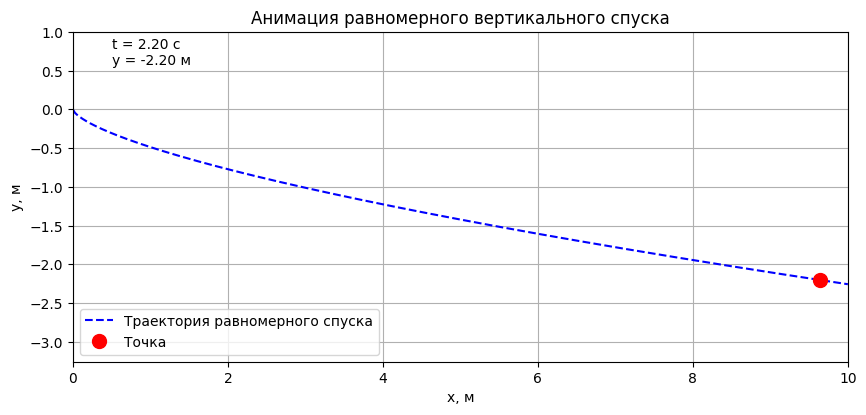

In [20]:
fig, ax = plt.subplots(figsize=(10, 8))

x_curve = np.linspace(0, x_max, 400)
y_curve = uniform_descent_curve(x_curve, v0, g, y0)

ax.plot(x_curve, y_curve, 'b--',label='Траектория равномерного спуска')
ax.set_xlim(0, x_max)
ax.set_ylim(min(y_curve) - 1, y0 + 1)
ax.set_title("Анимация равномерного вертикального спуска")
ax.set_xlabel("x, м")
ax.set_ylabel("y, м")
ax.grid(True)
ax.set_aspect('equal')

point, = ax.plot([], [], 'ro', markersize=10, label='Точка')
time_text = ax.text(0.05, 0.9, '', transform=ax.transAxes)

ax.legend(loc='lower left')

def init():
    point.set_data([], [])
    time_text.set_text('')
    return point, time_text

dt = 0.04
t_max = (y0 - y_curve[-1]) / v0

def animate(i):
    t = i * dt
    current_y = y0 - v0 * t

    if current_y > y_curve[-1]:
        current_x = ((y0 - current_y) / k)**(3/2)
    else:
        current_x = x_curve[-1]
        current_y = y_curve[-1]

    point.set_data([current_x], [current_y])
    time_text.set_text(f"t = {t:.2f} c\ny = {current_y:.2f} м")

    return point, time_text


anim = FuncAnimation(
    fig,
    animate,
    init_func=init,
    frames=int(t_max / dt),
    interval=40,
    blit=True
)

# fig.savefig("uniform_descent_curve.png", dpi=200)
# anim # если нужны кнопки
HTML(anim.to_html5_video()) # сжатый вариант

# 3.2. Бильярд в прямоугольнике с упругими отражениями

## 1. Постановка задачи

Рассмотрим прямоугольник
$$
\Omega = \{(x,y)\in\mathbb{R}^2:\ 0\le x\le a,\ 0\le y\le b\},
$$
где $a>0$, $b>0$ — длины сторон.

Материальная точка (бильярдный шар) движется **без сил** внутри $\Omega$ и
**упруго отражается** от границ. Упругое отражение означает:
- сохраняется модуль скорости $|\mathbf{v}|$;
- компонента скорости, нормальная к стенке, меняет знак, касательная — сохраняется.

Начальные данные:
$$
(x(0),y(0))=(x_0,y_0)\in \Omega,\qquad \mathbf{v}(0)=(v_x,v_y)\ne (0,0).
$$

## 2. Уравнения движения и граничные условия

Внутри области (между ударами) движение прямолинейное:
$$
x(t)=x_0+v_x t,\qquad y(t)=y_0+v_y t.
$$

На стенках:

- При ударе о вертикальную стенку ($x=0$ или $x=a$):
$$
(v_x,v_y)\mapsto (-v_x,\,v_y).
$$

- При ударе о горизонтальную стенку ($y=0$ или $y=b$):
$$
(v_x,v_y)\mapsto (v_x,\,-v_y).
$$

Энергия сохраняется:
$$
E=\frac{m}{2}(v_x^2+v_y^2)=\text{const}.
$$

## 3. Метод развертки (unfolding)

Отражения можно заменить **прямолинейным движением** в бесконечной “развернутой” плоскости.

Идея:
при отражении от стенки можно “отразить” сам прямоугольник, а траекторию продолжить прямой.

Тогда в развернутой плоскости точка движется без отражений:
$$
X(t)=x_0+v_x t,\qquad Y(t)=y_0+v_y t,
$$
а положение внутри исходного прямоугольника получается “сворачиванием” по правилу зеркального модуля.

Удобная формула зеркального модуля для отрезка $[0,L]$:

Пусть
$$
u = s \bmod (2L)\in [0,2L).
$$
Тогда
$$
\operatorname{fold}(s;L)=
\begin{cases}
u, & 0\le u\le L,\\
2L-u, & L<u<2L.
\end{cases}
$$

Итог:
$$
x(t)=\operatorname{fold}(x_0+v_x t;\,a),\qquad
y(t)=\operatorname{fold}(y_0+v_y t;\,b).
$$

## 4. Эквивалентное движение на торе

Рассмотрим координаты на “торе”:
$$
\xi(t)=(x_0+v_x t)\bmod(2a),\qquad
\eta(t)=(y_0+v_y t)\bmod(2b).
$$

Тогда $(\xi,\eta)$ движется равномерно по прямой на торе $\mathbb{T}^2$ с периодами $2a$ и $2b$:
$$
(\xi(t),\eta(t))=(\xi_0,\eta_0)+t\,(v_x,v_y)\ \ (\bmod\ (2a,2b)).
$$

Связь с исходными координатами:
$$
x(t)=\operatorname{fold}(\xi(t);a),\qquad y(t)=\operatorname{fold}(\eta(t);b).
$$

## 5. Типы траекторий: периодические и эргодические

Пусть скорость задана углом $\theta$:
$$
v_x=v\cos\theta,\qquad v_y=v\sin\theta.
$$

### 5.1 Условие периодичности

Движение на торе периодично тогда и только тогда, когда существует $T>0$ такое, что
$$
v_x T = 2a\,m,\qquad v_y T = 2b\,n,
$$
где $m,n\in\mathbb{Z}$.

Эквивалентно:
$$
\frac{v_x}{v_y}=\frac{a\,m}{b\,n},
$$
то есть
$$
\frac{v_x/a}{v_y/b}\in\mathbb{Q}.
$$

Иначе говоря, **периодичность** возникает при **рациональном наклоне** относительно масштабов прямоугольника.

### 5.2 Эргодичность (непериодичность и равномерное заполнение)

Если
$$
\frac{v_x/a}{v_y/b}\notin\mathbb{Q},
$$
то траектория на торе не замыкается и становится всюду плотной, а траектория в прямоугольнике
образует “квазипериодическое” движение с плотным заполнением (в типичном смысле).

## 6. Гамильтонова формулировка

Внутри области система — свободная частица:
$$
H(x,y,p_x,p_y)=\frac{1}{2m}(p_x^2+p_y^2),
$$
где $\mathbf{p}=m\mathbf{v}$.

Уравнения Гамильтона:
$$
\dot x=\frac{\partial H}{\partial p_x}=\frac{p_x}{m},\quad
\dot y=\frac{\partial H}{\partial p_y}=\frac{p_y}{m},\quad
\dot p_x=-\frac{\partial H}{\partial x}=0,\quad
\dot p_y=-\frac{\partial H}{\partial y}=0.
$$

Отражение от стенки — это каноническое преобразование импульса:
- при $x=0$ или $x=a$: $p_x\mapsto -p_x$,
- при $y=0$ или $y=b$: $p_y\mapsto -p_y$.

Энергия $H$ сохраняется всегда, а поток в фазовом пространстве сохраняет фазовый объем (лиувиллевость).

In [21]:
def fold(s, L):
    u = np.mod(s, 2*L)
    return np.where(u <= L, u, 2*L - u)

def billiard_trajectory(a, b, x0, y0, vx, vy, T, N=10000):
    t = np.linspace(0, T, N)
    X = x0 + vx * t
    Y = y0 + vy * t
    x = fold(X, a)
    y = fold(Y, b)
    return x, y, X, Y

In [22]:
# Параметры бильярда
a, b = 4.0, 3.0
x0, y0 = 1.0, 1.5

# Периодический случай
vx_p, vy_p = 2.0, 1.0
T_p = 20

# Эргодический случай
vx_e, vy_e = np.sqrt(2), 1.0
T_e = 100

# Траектории
x_p, y_p, X_p, Y_p = billiard_trajectory(a, b, x0, y0, vx_p, vy_p, T_p)
x_e, y_e, X_e, Y_e = billiard_trajectory(a, b, x0, y0, vx_e, vy_e, T_e)

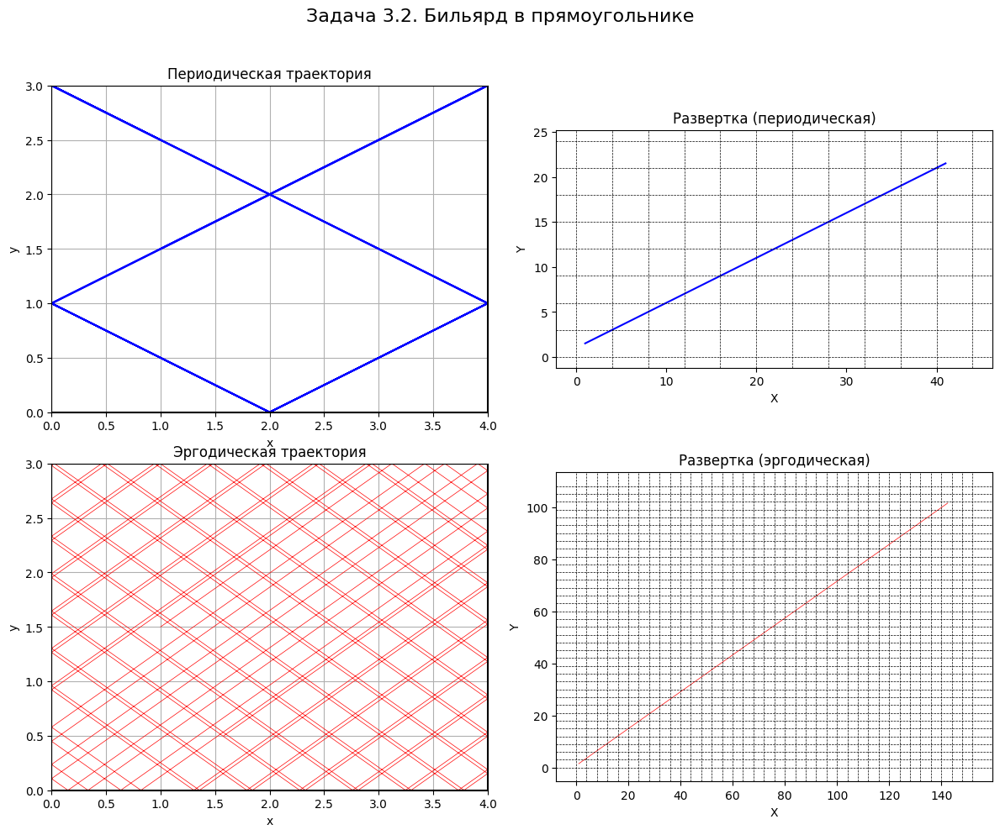

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Задача 3.2. Бильярд в прямоугольнике", fontsize=16)

axes[0, 0].plot(x_p, y_p, 'b-')
axes[0, 0].set_title("Периодическая траектория")

axes[1, 0].plot(x_e, y_e, 'r-', lw=0.5)
axes[1, 0].set_title("Эргодическая траектория")

for ax in [axes[0, 0], axes[1, 0]]:
    ax.plot([0, a, a, 0, 0], [0, 0, b, b, 0], 'k', lw=1.5)
    ax.set_xlim(0, a)
    ax.set_ylim(0, b)
    ax.set_aspect('equal')
    ax.grid(True)
    ax.set_xlabel("x")
    ax.set_ylabel("y")

axes[0, 1].plot(X_p, Y_p, 'b-')
axes[0, 1].set_title("Развертка (периодическая)")

axes[1, 1].plot(X_e, Y_e, 'r-', lw=0.5)
axes[1, 1].set_title("Развертка (эргодическая)")

for ax in [axes[0, 1], axes[1, 1]]:
    xmax, ymax = ax.get_xlim()[1], ax.get_ylim()[1]
    for i in range(int(xmax // a) + 2):
        ax.axvline(i * a, color='k', linestyle='--', lw=0.5)
    for j in range(int(ymax // b) + 2):
        ax.axhline(j * b, color='k', linestyle='--', lw=0.5)
    ax.set_aspect('equal')
    ax.set_xlabel("X")
    ax.set_ylabel("Y")

plt.tight_layout(rect=[0, 0, 1, 0.95])
# plt.savefig("billiard_static.png", dpi=150)
plt.show()

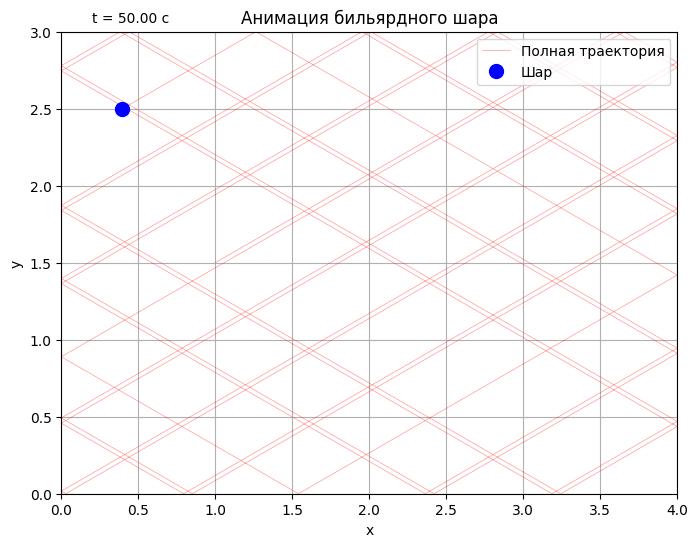

In [24]:
# Параметры
vx, vy = np.sqrt(3), 1.0
total_time = 50.0
frames = 500

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_title("Анимация бильярдного шара")
ax.set_xlim(0, a)
ax.set_ylim(0, b)
ax.set_aspect('equal')
ax.grid(True)
ax.set_xlabel("x")
ax.set_ylabel("y")

x_bg, y_bg, _, _ = billiard_trajectory(a, b, x0, y0, vx, vy, total_time)
ax.plot(x_bg, y_bg, 'r-', lw=0.5, alpha=0.4, label="Полная траектория")

ball, = ax.plot([], [], 'bo', ms=10, label="Шар")
time_text = ax.text(0.05, 1.02, '', transform=ax.transAxes)

ax.legend(loc='upper right')

def init():
    ball.set_data([], [])
    time_text.set_text('')
    return ball, time_text

def animate(i):
    t = (i / (frames - 1)) * total_time

    X = x0 + vx * t
    Y = y0 + vy * t

    x = fold(X, a)
    y = fold(Y, b)

    ball.set_data([x], [y])
    time_text.set_text(f"t = {t:.2f} c")
    return ball, time_text

anim = FuncAnimation(
    fig,
    animate,
    init_func=init,
    frames=frames,
    interval=20,
    blit=True
)

# anim # если нужны кнопки
HTML(anim.to_html5_video()) # сжатый вариант

# 3.3. Задача о цепной линии

## 1. Постановка

Рассмотрим однородную тяжелую нерастяжимую гибкую нить (цепь), подвешенную за два конца и находящуюся в равновесии в поле тяжести.

Введем декартову систему координат: ось $x$ — горизонтально, ось $y$ — вертикально вверх.

Пусть форма нити описывается графиком
$$
y = y(x).
$$

Плотность массы на единицу длины (линейная плотность) обозначим через $\lambda$, тогда вес единицы длины:
$$
w = \lambda g.
$$

Нить гибкая, поэтому внутреннее усилие — **натяжение** $\mathbf{T}$, направленное вдоль касательной к кривой.

## 2. Равновесие элемента цепи и вывод дифференциального уравнения

Рассмотрим малый элемент цепи длины $ds$ между $x$ и $x+dx$.

На него действуют:
- натяжение слева: $\mathbf{T}(x)$,
- натяжение справа: $\mathbf{T}(x+dx)$,
- сила тяжести: $d\mathbf{F}_g = (0,-w\,ds)$.

Условие равновесия:
$$
d\mathbf{T} + d\mathbf{F}_g = \mathbf{0}.
$$

Разложим натяжение на компоненты:
$$
\mathbf{T} = (T_x, T_y).
$$

Так как внешних горизонтальных сил нет, горизонтальная компонента постоянна:
$$
T_x = H = \text{const}.
$$

Вертикальная компонента меняется из-за веса:
$$
dT_y = w\,ds.
$$

Геометрия кривой:
$$
ds = \sqrt{1+(y')^2}\,dx,
\qquad
\tan\theta = y',
\qquad
\frac{T_y}{T_x}=\tan\theta = y'.
$$

Значит:
$$
T_y = H\,y'.
$$

Дифференцируем по $x$:
$$
\frac{dT_y}{dx} = H\,y''.
$$

С другой стороны:
$$
\frac{dT_y}{dx} = w\,\frac{ds}{dx} = w\sqrt{1+(y')^2}.
$$

Приравнивая, получаем дифференциальное уравнение цепной линии:
$$
H\,y'' = w\sqrt{1+(y')^2}.
$$

Введем параметр
$$
a=\frac{H}{w},
$$
тогда уравнение принимает стандартный вид:
$$
y'' = \frac{1}{a}\sqrt{1+(y')^2}.
$$

## 3. Решение уравнения методом разделения переменных

Обозначим
$$
p = y'(x).
$$

Тогда:
$$
p' = y'' = \frac{1}{a}\sqrt{1+p^2}.
$$

Разделяем переменные:
$$
\frac{dp}{\sqrt{1+p^2}} = \frac{dx}{a}.
$$

Интегрируем:
$$
\operatorname{arsinh}(p) = \frac{x}{a} + C_1.
$$

Отсюда:
$$
p = \sinh\!\left(\frac{x}{a} + C_1\right),
\qquad
y'=\sinh\!\left(\frac{x}{a}+C_1\right).
$$

Интегрируем еще раз:
$$
y = a\cosh\!\left(\frac{x}{a}+C_1\right)+C_2.
$$

Перепараметризуем константы:
$$
C_1 = -\frac{x_c}{a},\qquad C_2 = y_c.
$$

Итоговое уравнение цепной линии:
$$
\boxed{
y(x)=y_c + a\cosh\!\left(\frac{x-x_c}{a}\right)
}
$$

## 4. Физический смысл параметра $a$

Напомним:
$$
a=\frac{H}{w}=\frac{H}{\lambda g}.
$$

- Чем больше горизонтальное натяжение $H$, тем больше $a$ и тем **более “плоская”** цепь (меньше провисание).
- Чем больше вес на единицу длины $w=\lambda g$, тем меньше $a$ и тем **сильнее провисает** цепь.

Натяжение по модулю:
$$
T = \sqrt{T_x^2+T_y^2}=\sqrt{H^2+(Hy')^2}=H\sqrt{1+(y')^2}
=H\cosh\!\left(\frac{x-x_c}{a}\right).
$$

Минимальное натяжение достигается в нижней точке $x=x_c$:
$$
T_{\min}=H.
$$

In [25]:
# Параметры
x_min, x_max = -5.0, 5.0
x = np.linspace(x_min, x_max, 600)
a_values = [0.6, 1.0, 2.0, 4.0]
xc, yc = 0.0, 0.0


def catenary(x, a, xc=0.0, yc=0.0):
    return yc + a * np.cosh((x - xc)/a)

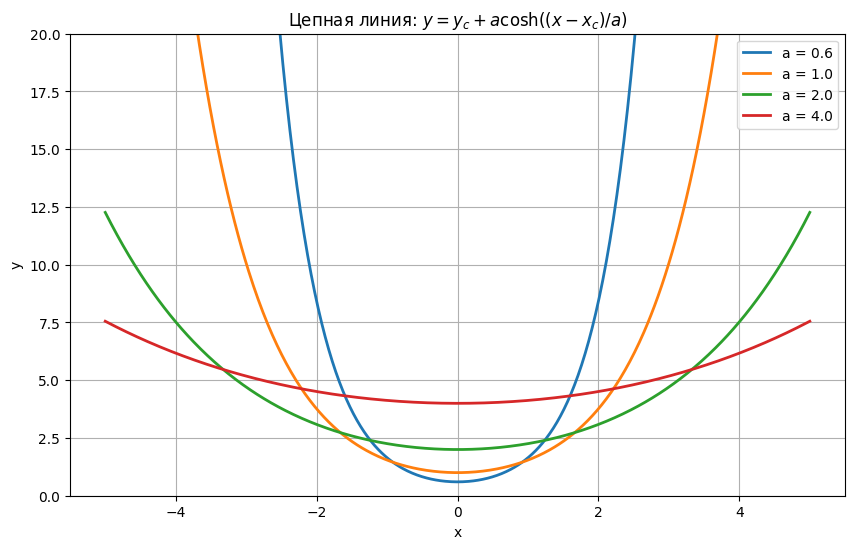

In [26]:
fig, ax = plt.subplots(figsize=(10, 6))

for a in a_values:
    y = catenary(x, a, xc, yc)
    ax.plot(x, y, lw=2, label=f"a = {a}")

ax.set_title("Цепная линия: $y = y_c + a\\cosh((x-x_c)/a)$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True)
ax.set_ylim(0, 20)
ax.legend()

# fig.savefig("catenary_static.png", dpi=200)
plt.show()

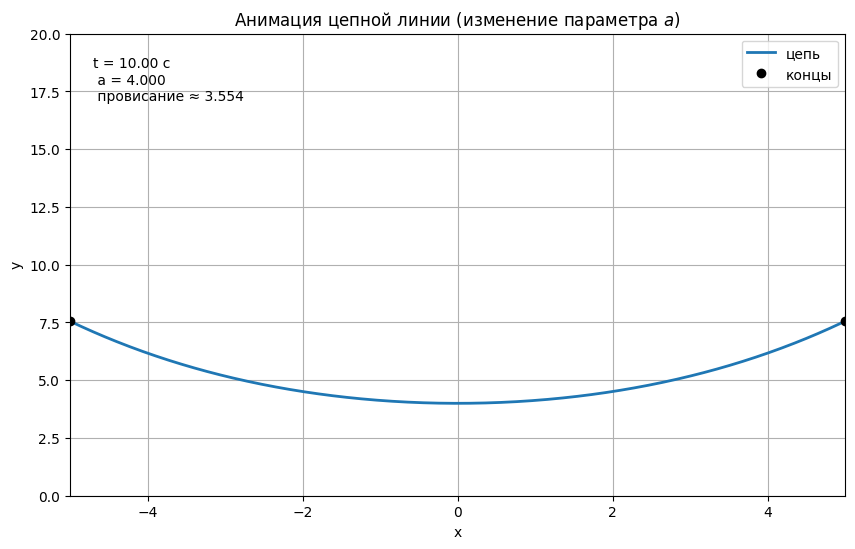

In [27]:
# Параметры
a_min, a_max = min(a_values), max(a_values)
total_time = 10.0
anim_frames = 400

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_title("Анимация цепной линии (изменение параметра $a$)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True)

y_ref = catenary(x, a_min, xc, yc)
ax.set_xlim(x_min, x_max)
ax.set_ylim(0, 20)

line, = ax.plot([], [], lw=2, label="цепь")
ends, = ax.plot([], [], 'ko', ms=6, label="концы")
time_text = ax.text(0.03, 0.95, "", transform=ax.transAxes, va="top")

ax.legend(loc="upper right")

def init():
    line.set_data([], [])
    ends.set_data([], [])
    time_text.set_text("")
    return line, ends, time_text

def animate(i):
    t = (i / (anim_frames - 1)) * total_time

    mid = 0.5 * (a_min + a_max)
    amp = 0.5 * (a_max - a_min)
    a = mid + amp * np.cos(2 * np.pi * t / total_time)

    y = catenary(x, a, xc, yc)

    sag = 0.5 * (y[0] + y[-1]) - y.min()

    line.set_data(x, y)
    ends.set_data([x[0], x[-1]], [y[0], y[-1]])
    time_text.set_text(f"t = {t:.2f} c\n a = {a:.3f}\n провисание ≈ {sag:.3f}")

    return line, ends, time_text

anim = FuncAnimation(
    fig,
    animate,
    init_func=init,
    frames=anim_frames,
    interval=25,
    blit=True
)

# anim # если нужны кнопки
HTML(anim.to_html5_video()) # сжатый вариант

# 3.4. Задача о таутохроне

## 1. Постановка задачи

Найти такую гладкую кривую в вертикальной плоскости, по которой материальная точка массы $m$ скользит без трения под действием силы тяжести так, что **время спуска до нижней точки** не зависит от начального положения на кривой.

Введём координаты: ось $y$ направим вверх. Пусть нижняя точка кривой — точка $O$ (минимум потенциальной энергии).  
Удобно параметризовать движение по дуге кривой длиной $s$ от нижней точки:
- $s=0$ в точке $O$,
- $s>0$ выше по кривой.

Пусть высота точки над нижней точкой равна $y(s)\ge 0$ (по модулю, т.е. $y$ — вертикальный подъём над нижней точкой).

## 2. Интегральное уравнение для времени спуска

Энергия сохраняется (трения нет). Если точка стартует из положения $s=s_0$ без начальной скорости, то:

$$
\frac{m v^2}{2} + m g\,y(s) = m g\,y(s_0).
$$

Отсюда скорость вдоль кривой:

$$
v(s)=\sqrt{2g\,(y(s_0)-y(s))}.
$$

Элемент времени:

$$
dt = \frac{ds}{v(s)}=\frac{ds}{\sqrt{2g\,(y(s_0)-y(s))}}.
$$

Время спуска из $s_0$ до $0$:

$$
T(s_0)=\int_{0}^{s_0}\frac{ds}{\sqrt{2g\,(y(s_0)-y(s))}}.
$$

Требование таутохронности:

$$
T(s_0)\equiv T_0=\text{const для всех } s_0.
$$

Это и есть **интегральное уравнение** для неизвестной функции $y(s)$.

## 3. Сведение к уравнению Абеля

Пусть $y$ монотонно возрастает при увеличении $s$ (выше — больше высота). Тогда можно рассматривать обратную функцию $s=s(y)$ и заменить переменную интегрирования.

Так как $ds = s'(y)\,dy$, то при фиксированном $y_0=y(s_0)$:

$$
T_0 = \int_{0}^{y_0} \frac{s'(y)\,dy}{\sqrt{2g\,(y_0-y)}}.
$$

Умножая на $\sqrt{2g}$, получаем:

$$
\int_{0}^{y_0} \frac{s'(y)\,dy}{\sqrt{y_0-y}} = \sqrt{2g}\,T_0.
$$

Это уравнение Абеля вида:

$$
\int_{0}^{y_0}\frac{f(y)\,dy}{\sqrt{y_0-y}} = C,
\qquad f(y)=s'(y),\quad C=\sqrt{2g}\,T_0.
$$

Известное решение уравнения Абеля (инверсия) даёт:

Если
$$
\int_{0}^{y}\frac{f(u)\,du}{\sqrt{y-u}} = C,
$$
то
$$
f(y) = \frac{C}{\pi}\,\frac{d}{dy}\int_{0}^{y}\frac{du}{\sqrt{y-u}}
= \frac{C}{\pi}\,\frac{d}{dy}\left(2\sqrt{y}\right)
= \frac{C}{\pi}\,\frac{1}{\sqrt{y}}.
$$

Следовательно:

$$
s'(y)=\frac{\sqrt{2g}\,T_0}{\pi}\,\frac{1}{\sqrt{y}}.
$$

Интегрируем:

$$
s(y)=\frac{\sqrt{2g}\,T_0}{\pi}\int \frac{dy}{\sqrt{y}}
= \frac{\sqrt{2g}\,T_0}{\pi}\cdot 2\sqrt{y}.
$$

С учётом $s(0)=0$:

$$
s(y)=\frac{2\sqrt{2g}\,T_0}{\pi}\sqrt{y}.
$$

Выражаем высоту через длину дуги:

$$
y(s)=\left(\frac{\pi}{2\sqrt{2g}\,T_0}\right)^2 s^2.
$$

Итак, **таутохронность эквивалентна тому, что высота пропорциональна квадрату длины дуги**:

$$
\boxed{y(s)=\frac{s^2}{8R}},
$$

где параметр $R$ введён так, что

$$
T_0=\pi\sqrt{\frac{R}{g}}.
$$

## 4. Доказательство изохронности через уравнение движения

Из $y(s)=\dfrac{s^2}{8R}$ получаем компоненту силы вдоль касательной:

Потенциальная энергия:
$$
U(s)=mg\,y(s)=mg\,\frac{s^2}{8R}.
$$

Сила вдоль дуги:
$$
F_s=-\frac{dU}{ds}=-mg\,\frac{s}{4R}.
$$

Уравнение движения вдоль дуги:
$$
m\ddot s = -mg\,\frac{s}{4R}
\quad\Rightarrow\quad
\ddot s + \frac{g}{4R}s = 0.
$$

Это уравнение гармонического осциллятора с частотой
$$
\omega=\sqrt{\frac{g}{4R}}.
$$

Время от максимального отклонения до $s=0$ — четверть периода:
$$
T_0=\frac{\pi}{2\omega}=\pi\sqrt{\frac{R}{g}},
$$
и оно **не зависит от амплитуды** (начального положения). Это и доказывает таутохронность.

## 5. Геометрическая форма кривой: циклоидa

Остаётся найти кривую, для которой
$$
y(s)=\frac{s^2}{8R}.
$$

Из классической геометрии известно, что это выполняется для **циклоиды** — траектории точки окружности радиуса $R$, катящейся без скольжения.

Параметрические уравнения циклоиды:

$$
\boxed{
\begin{aligned}
x(\theta) &= R(\theta - \sin\theta),\\
y(\theta) &= R(1 - \cos\theta).
\end{aligned}}
$$

## 6. Итог

**Таутохронная кривая** (изохронная кривая) при скольжении без трения в поле тяжести — это **циклоидa**.

Время спуска до нижней точки одинаково для всех стартовых положений и равно:

$$
\boxed{
T_0=\pi\sqrt{\frac{R}{g}}.
}
$$

In [28]:
# Параметры
g = 9.81
R = 1.5
theta_max = np.pi
N = 1200

omega = np.sqrt(g / (4*R))
T_taut = np.pi / (2*omega)
total_time = T_taut * 1.05
anim_frames = 500

def cycloid(theta, R):
    x = R * (theta + np.sin(theta))
    y = R * (1 - np.cos(theta))
    return x, y

def theta_of_t(t, theta0, omega):
    A = np.sin(theta0/2)
    val = A * np.cos(omega*t)
    val = np.clip(val, -1.0, 1.0)
    return 2*np.arcsin(val)

theta0_list = [theta_max, 0.8*theta_max, 0.6*theta_max, 0.4*theta_max]
colors = ['r', 'g', 'm', 'orange']

/tmp/ipykernel_8221/1825526505.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  ax.text(float(x0), float(y0), f"  θ0={th0:.2f}", va='center')


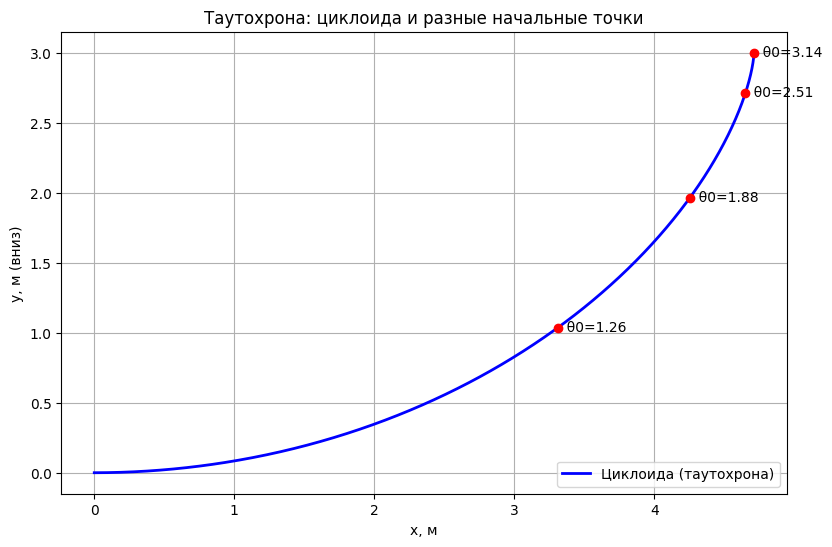

In [29]:
theta = np.linspace(0, theta_max, N)
x_curve, y_curve = cycloid(theta, R)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(x_curve, y_curve, 'b-', lw=2, label='Циклоида (таутохрона)')

for th0 in theta0_list:
    x0, y0 = cycloid(np.array([th0]), R)
    ax.plot(x0, y0, 'ro')
    ax.text(float(x0), float(y0), f"  θ0={th0:.2f}", va='center')

ax.set_title("Таутохрона: циклоидa и разные начальные точки")
ax.set_xlabel("x, м")
ax.set_ylabel("y, м (вниз)")
ax.grid(True)
ax.set_aspect('equal')
ax.legend(loc='lower right')

# fig.savefig("tautochrone_static.png", dpi=200)
plt.show()

/tmp/ipykernel_8221/1111591408.py:55: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  balls[j].set_data([float(x)], [float(y)])
/tmp/ipykernel_8221/1111591408.py:72: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gen_point.set_data([float(px)], [float(py)])


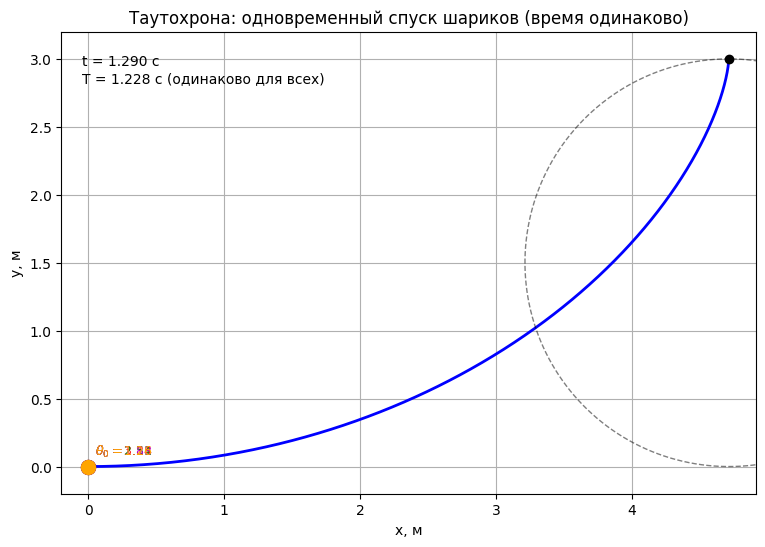

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))

th = np.linspace(0, theta_max, 1200)
x_curve, y_curve = cycloid(th, R)
ax.plot(x_curve, y_curve, 'b-', lw=2, label='Циклоида')

ax.set_xlim(-0.2, x_curve.max() + 0.2)
ax.set_ylim(-0.2, y_curve.max() + 0.2)
ax.set_title("Таутохрона: одновременный спуск шариков (время одинаково)")
ax.set_xlabel("x, м")
ax.set_ylabel("y, м")
ax.grid(True)
ax.set_aspect('equal')

balls = []
for c in colors[:len(theta0_list)]:
    bobj, = ax.plot([], [], 'o', ms=10, color=c)
    balls.append(bobj)

labels = []
for j, theta0 in enumerate(theta0_list):
    txt = ax.text(
        0, 0, "",
        fontsize=9,
        color=colors[j],
        ha='left', va='bottom'
    )
    labels.append(txt)

time_text = ax.text(0.03, 0.95, '', transform=ax.transAxes, va='top')

show_rolling_circle = True
circle_line, = ax.plot([], [], 'k--', lw=1, alpha=0.5)
gen_point, = ax.plot([], [], 'ko', ms=6)

def init():
    for bobj in balls:
        bobj.set_data([], [])
    for txt in labels:
        txt.set_text("")
    time_text.set_text('')
    circle_line.set_data([], [])
    gen_point.set_data([], [])
    return (*balls, *labels, time_text, circle_line, gen_point)

def animate(i):
    t = (i / (anim_frames - 1)) * total_time

    for j, theta0 in enumerate(theta0_list):
        if t <= T_taut:
            th_t = theta_of_t(t, theta0, omega)
        else:
            th_t = 0.0
        x, y = cycloid(np.array([th_t]), R)
        balls[j].set_data([float(x)], [float(y)])

        labels[j].set_position((x + 0.05, y + 0.05))
        labels[j].set_text(rf"$\theta_0={theta0:.2f}$")

    time_text.set_text(f"t = {t:.3f} c\nT = {T_taut:.3f} c (одинаково для всех)")

    if show_rolling_circle:
        th_roll = min(t / total_time * theta_max, theta_max)
        cx, cy = R * th_roll, R

        ang = np.linspace(0, 2*np.pi, 200)
        circ_x = cx + R*np.cos(ang)
        circ_y = cy + R*np.sin(ang)
        circle_line.set_data(circ_x, circ_y)

        px, py = cycloid(np.array([th_roll]), R)
        gen_point.set_data([float(px)], [float(py)])
    else:
        circle_line.set_data([], [])
        gen_point.set_data([], [])

    return (*balls, time_text, circle_line, gen_point)

anim = FuncAnimation(
    fig,
    animate,
    init_func=init,
    frames=anim_frames,
    interval=20,
    blit=True
)

# anim # если нужны кнопки
HTML(anim.to_html5_video()) # сжатый вариант

# 3.5. Движение математического маятника

## 1. Постановка

Рассмотрим точечную массу $m$ на невесомом нерастяжимом стержне длины $l$ в поле тяжести $g$.
Отклонение маятника от вертикали зададим углом $\theta(t)$.

Координаты груза:
$$
x=l\sin\theta,\qquad y=-l\cos\theta.
$$

Скорость:
$$
\dot x=l\cos\theta\,\dot\theta,\qquad
\dot y=l\sin\theta\,\dot\theta,
$$
$$
v^2=\dot x^2+\dot y^2=l^2\dot\theta^2.
$$

## 2. Вывод уравнения движения (2-й закон Ньютона / Лагранж)

Кинетическая и потенциальная энергии:
$$
T=\frac{m}{2}l^2\dot\theta^2,
\qquad
V=mgl(1-\cos\theta).
$$

Лагранжиан $L=T-V$:
$$
L=\frac{m}{2}l^2\dot\theta^2 - mgl(1-\cos\theta).
$$

Уравнение Лагранжа:
$$
\frac{d}{dt}\left(\frac{\partial L}{\partial\dot\theta}\right)-\frac{\partial L}{\partial\theta}=0
\quad\Rightarrow\quad
ml^2\ddot\theta + mgl\sin\theta=0.
$$

Итак:
$$
\boxed{\ddot\theta+\frac{g}{l}\sin\theta=0.}
$$

## 3. Интеграл энергии и фазовая плоскость

Умножим уравнение на $\dot\theta$ и проинтегрируем:
$$
\frac{d}{dt}\left(\frac{1}{2}\dot\theta^2+\frac{g}{l}(1-\cos\theta)\right)=0.
$$

Энергия на единицу массы:
$$
\boxed{
E=\frac{1}{2}l^2\dot\theta^2 + gl(1-\cos\theta)=\text{const}.
}
$$

На фазовой плоскости $(\theta,\dot\theta)$ уровни энергии задают траектории.

- **Колебания**: энергия ниже вершины ($E<2gl$) — замкнутые траектории вокруг $(0,0)$.
- **Сепаратриса**: $E=2gl$ — траектория, проходящая через $\theta=\pm\pi$, разделяет колебания и вращения.
- **Вращения**: $E>2gl$ — незамкнутые траектории, соответствующие непрерывному вращению.

## 4. Линеаризация (малые углы)

При $|\theta|\ll 1$:
$$
\sin\theta \approx \theta,
$$
получаем гармонический осциллятор:
$$
\boxed{\ddot\theta+\omega_0^2\theta=0,\qquad \omega_0=\sqrt{\frac{g}{l}}.}
$$

Решение:
$$
\theta(t)=A\cos(\omega_0 t+\varphi).
$$

Период малых колебаний:
$$
\boxed{T_0=2\pi\sqrt{\frac{l}{g}}.}
$$

## 5. Нелинейные эффекты и точный период

Для амплитуды $\theta_0$ (максимальный угол), где $\dot\theta=0$, из энергии:
$$
\frac{1}{2}l^2\dot\theta^2=gl(\cos\theta-\cos\theta_0).
$$

Отсюда:
$$
\dot\theta=\pm\sqrt{\frac{2g}{l}\,(\cos\theta-\cos\theta_0)}.
$$

Период колебаний:
$$
T(\theta_0)=4\int_{0}^{\theta_0}\frac{d\theta}{\sqrt{\frac{2g}{l}(\cos\theta-\cos\theta_0)}}.
$$

Стандартной заменой получаем выражение через полный эллиптический интеграл:
$$
\boxed{
T(\theta_0)=4\sqrt{\frac{l}{g}}\,K(k),\qquad
k=\sin\frac{\theta_0}{2},
}
$$
где $K(k)$ — полный эллиптический интеграл первого рода.

При $\theta_0\to 0$ имеем $K(0)=\frac{\pi}{2}$ и $T(\theta_0)\to T_0$.

При росте амплитуды период **увеличивается**.

In [31]:
# Параметры
g = 9.81
l = 1.0
w0 = np.sqrt(g / l)

# Численное решение (RK4) для нелинейного маятника
def pendulum_rk4(theta0, omega0, t_max, dt):
    n = int(t_max / dt) + 1
    t = np.linspace(0, t_max, n)
    theta = np.zeros(n)
    omega = np.zeros(n)
    theta[0] = theta0
    omega[0] = omega0

    def f(th, om):
        dth = om
        dom = -(g/l) * np.sin(th)
        return dth, dom

    for i in range(n-1):
        th, om = theta[i], omega[i]

        k1_th, k1_om = f(th, om)
        k2_th, k2_om = f(th + 0.5*dt*k1_th, om + 0.5*dt*k1_om)
        k3_th, k3_om = f(th + 0.5*dt*k2_th, om + 0.5*dt*k2_om)
        k4_th, k4_om = f(th + dt*k3_th, om + dt*k3_om)

        theta[i+1] = th + (dt/6)*(k1_th + 2*k2_th + 2*k3_th + k4_th)
        omega[i+1] = om + (dt/6)*(k1_om + 2*k2_om + 2*k3_om + k4_om)

    return t, theta, omega

# Оценка периода по нулям (для колебаний)
def estimate_period(t, theta):
    idx = np.where((theta[:-1] < 0) & (theta[1:] >= 0))[0]
    if len(idx) < 2:
        return np.nan
    
    zeros = []
    for i in idx:
        t0, t1 = t[i], t[i+1]
        y0, y1 = theta[i], theta[i+1]
        tz = t0 - y0*(t1-t0)/(y1-y0)
        zeros.append(tz)
    zeros = np.array(zeros)
    
    if len(zeros) < 3:
        return np.nan
    return np.mean(np.diff(zeros[::1]))

# Данные для theta(t)
dt = 0.001
t_max = 10.0

ICs = [
    (0.2, 0.0, "малые углы"),
    (1.0, 0.0, "средняя амплитуда"),
    (2.5, 0.0, "близко к сепаратрисе"),
]

# Фазовый портрет + сепаратриса
theta_grid = np.linspace(-np.pi, np.pi, 800)
omega_sep = np.sqrt((2*g/l) * (1 + np.cos(theta_grid)))

# Период от амплитуды (численно)
amps = np.linspace(0.1, 3.0, 20)
periods = []
for A in amps:
    t, th, om = pendulum_rk4(A, 0.0, t_max=20.0, dt=dt)
    T_est = estimate_period(t, th)
    periods.append(T_est)
periods = np.array(periods)
T0 = 2*np.pi*np.sqrt(l/g)

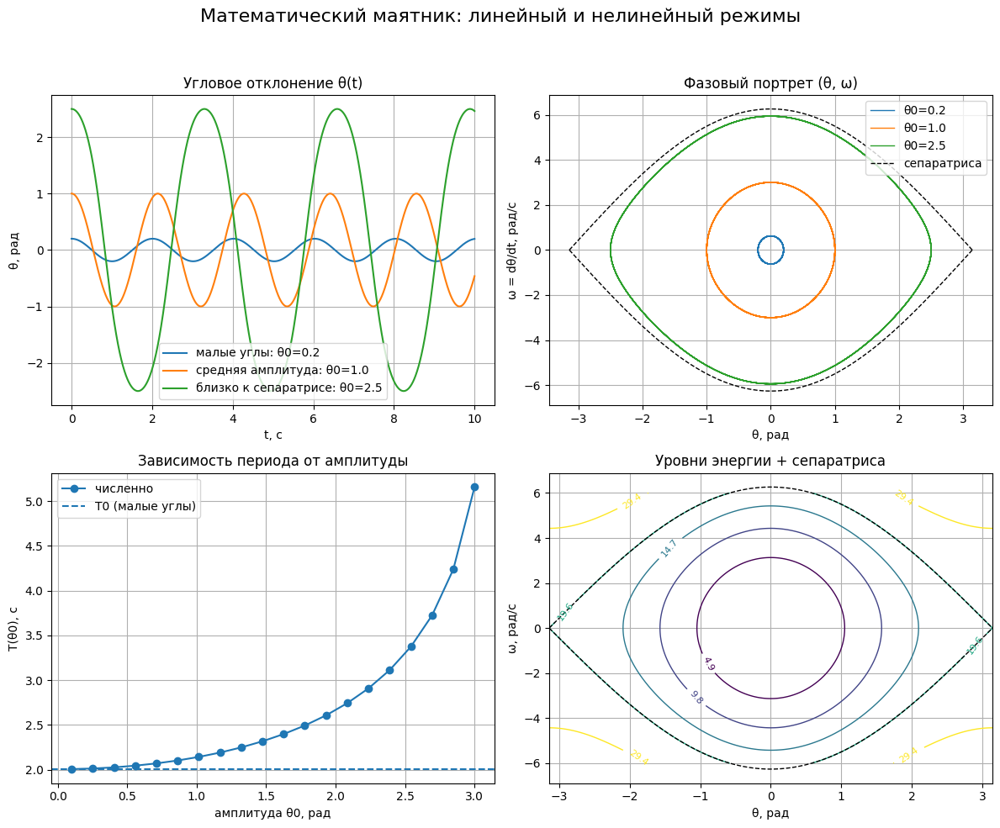

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Математический маятник: линейный и нелинейный режимы", fontsize=16)

ax = axes[0, 0]
for (th0, om0, label) in ICs:
    t, th, om = pendulum_rk4(th0, om0, t_max=t_max, dt=dt)
    ax.plot(t, th, label=f"{label}: θ0={th0}")
ax.set_title("Угловое отклонение θ(t)")
ax.set_xlabel("t, c")
ax.set_ylabel("θ, рад")
ax.grid(True)
ax.legend()

ax = axes[0, 1]
for (th0, om0, label) in ICs:
    t, th, om = pendulum_rk4(th0, om0, t_max=20.0, dt=dt)
    ax.plot(th, om, lw=1, label=f"θ0={th0}")
ax.plot(theta_grid,  omega_sep, 'k--', lw=1, label="сепаратриса")
ax.plot(theta_grid, -omega_sep, 'k--', lw=1)
ax.set_title("Фазовый портрет (θ, ω)")
ax.set_xlabel("θ, рад")
ax.set_ylabel("ω = dθ/dt, рад/с")
ax.grid(True)
ax.legend()

ax = axes[1, 0]
ax.plot(amps, periods, 'o-', label="численно")
ax.axhline(T0, linestyle='--', label="T0 (малые углы)")
ax.set_title("Зависимость периода от амплитуды")
ax.set_xlabel("амплитуда θ0, рад")
ax.set_ylabel("T(θ0), c")
ax.grid(True)
ax.legend()

ax = axes[1, 1]
TH, OM = np.meshgrid(np.linspace(-np.pi, np.pi, 300), np.linspace(-6, 6, 300))
E = 0.5*(l**2)*(OM**2) + g*l*(1 - np.cos(TH))
cs = ax.contour(TH, OM, E, levels=[0.5*g*l, 1.0*g*l, 1.5*g*l, 2.0*g*l, 3.0*g*l], linewidths=1)
ax.clabel(cs, inline=True, fontsize=8, fmt="%.1f")
ax.plot(theta_grid,  omega_sep, 'k--', lw=1)
ax.plot(theta_grid, -omega_sep, 'k--', lw=1)
ax.set_title("Уровни энергии + сепаратриса")
ax.set_xlabel("θ, рад")
ax.set_ylabel("ω, рад/с")
ax.grid(True)

plt.tight_layout(rect=[0, 0, 1, 0.95])
# plt.savefig("pendulum_static.png", dpi=200)
plt.show()

In [33]:
# Параметры
theta0 = 1.2 
omega0 = 0.0

dt = 0.02
anim_frames = 1200

# RK4 шаг для анимации
def rk4_step(theta, omega, dt):
    def f(th, om):
        return om, -(g/l)*np.sin(th)

    k1_th, k1_om = f(theta, omega)
    k2_th, k2_om = f(theta + 0.5*dt*k1_th, omega + 0.5*dt*k1_om)
    k3_th, k3_om = f(theta + 0.5*dt*k2_th, omega + 0.5*dt*k2_om)
    k4_th, k4_om = f(theta + dt*k3_th, omega + dt*k3_om)

    theta_new = theta + (dt/6)*(k1_th + 2*k2_th + 2*k3_th + k4_th)
    omega_new = omega + (dt/6)*(k1_om + 2*k2_om + 2*k3_om + k4_om)
    return theta_new, omega_new

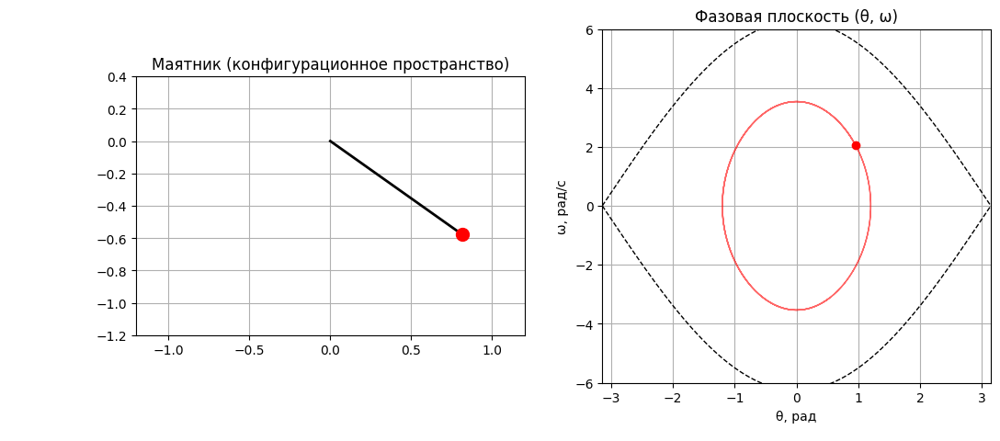

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.set_title("Маятник (конфигурационное пространство)")
ax1.set_aspect('equal')
ax1.grid(True)
ax1.set_xlim(-l-0.2, l+0.2)
ax1.set_ylim(-l-0.2, 0.4)

pivot = (0.0, 0.0)
rod, = ax1.plot([], [], 'k-', lw=2)
bob, = ax1.plot([], [], 'ro', ms=10)

ax2.set_title("Фазовая плоскость (θ, ω)")
ax2.set_xlabel("θ, рад")
ax2.set_ylabel("ω, рад/с")
ax2.grid(True)
ax2.set_xlim(-np.pi, np.pi)
ax2.set_ylim(-6, 6)

theta_grid = np.linspace(-np.pi, np.pi, 800)
omega_sep = np.sqrt((2*g/l)*(1 + np.cos(theta_grid)))
ax2.plot(theta_grid,  omega_sep, 'k--', lw=1)
ax2.plot(theta_grid, -omega_sep, 'k--', lw=1)

pt, = ax2.plot([], [], 'ro', ms=6)
trail, = ax2.plot([], [], 'r-', lw=1, alpha=0.6)

info = fig.text(0.01, 0.01, "", fontsize=10)

tail = 300
buf_th, buf_om = [], []

state = {"theta": theta0, "omega": omega0, "t": 0.0}

def init():
    rod.set_data([], [])
    bob.set_data([], [])
    pt.set_data([], [])
    trail.set_data([], [])
    info.set_text("")
    buf_th.clear()
    buf_om.clear()
    return rod, bob, pt, trail, info

def animate(i):
    th = state["theta"]
    om = state["omega"]
    t = state["t"]

    th, om = rk4_step(th, om, dt)
    t += dt

    th_plot = (th + np.pi) % (2*np.pi) - np.pi

    state["theta"], state["omega"], state["t"] = th, om, t

    x = l * np.sin(th)
    y = -l * np.cos(th)

    rod.set_data([pivot[0], x], [pivot[1], y])
    bob.set_data([x], [y])

    buf_th.append(th_plot)
    buf_om.append(om)
    if len(buf_th) > tail:
        del buf_th[:len(buf_th)-tail]
        del buf_om[:len(buf_om)-tail]

    pt.set_data([th_plot], [om])
    trail.set_data(buf_th, buf_om)

    info.set_text(f"t = {t:.2f} c | θ0 = {theta0:.2f} | ω0 = {omega0:.2f}")

    return rod, bob, pt, trail, info

anim = FuncAnimation(
    fig,
    animate,
    init_func=init,
    frames=anim_frames,
    interval=20,
    blit=True
)

# anim # если нужны кнопки
HTML(anim.to_html5_video()) # сжатый вариант